In [4]:
import pandas as pd
from fredapi import Fred
fred = Fred(api_key='9e7a32c0129807828b6dbb05a4d44672')
cpi_data = fred.get_series('CP0000DEM086NEST')
df = pd.DataFrame({'ds': cpi_data.index, 'y': cpi_data.values})
df = df.dropna()
print(df.tail())



            ds       y
364 2026-05-01  102.54
365 2026-06-01  102.32
366 2026-07-01  103.20
367 2026-08-01  103.36
368 2026-09-01  103.93


Matplotlib is building the font cache; this may take a moment.


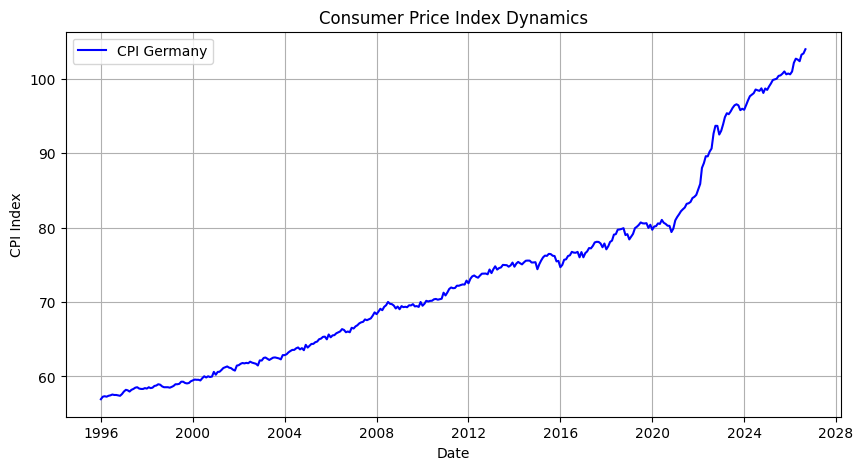

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(df['ds'], df['y'], color='blue', label='CPI Germany')
plt.title('Consumer Price Index Dynamics')
plt.xlabel('Date')
plt.ylabel('CPI Index')
plt.grid(True)
plt.legend()
plt.show()


In [6]:

train = df.iloc[:-12]


test = df.iloc[-12:]

print(f"Training months: {len(train)}")
print(f"Testing months: {len(test)}")

Training months: 357
Testing months: 12


In [7]:
from prophet import Prophet

model = Prophet(yearly_seasonality=True, daily_seasonality=False)

model.fit(train)

future = model.make_future_dataframe(periods=12, freq='MS')

forecast = model.predict(future)

Importing plotly failed. Interactive plots will not work.
19:48:04 - cmdstanpy - INFO - Chain [1] start processing
19:48:06 - cmdstanpy - INFO - Chain [1] done processing


In [9]:
!pip install scikit-learn

     |████████████████████████████████| 11.1 MB 1.7 MB/s eta 0:00:01
     |████████████████████████████████| 30.3 MB 1.5 MB/s eta 0:00:011
     |████████████████████████████████| 309 kB 35.7 MB/s eta 0:00:01
You should consider upgrading via the '/Users/yatsukkatia/Desktop/ukraine_inflation_ml/venv/bin/python3 -m pip install --upgrade pip' command.


Average model error (MAPE): 2.10%


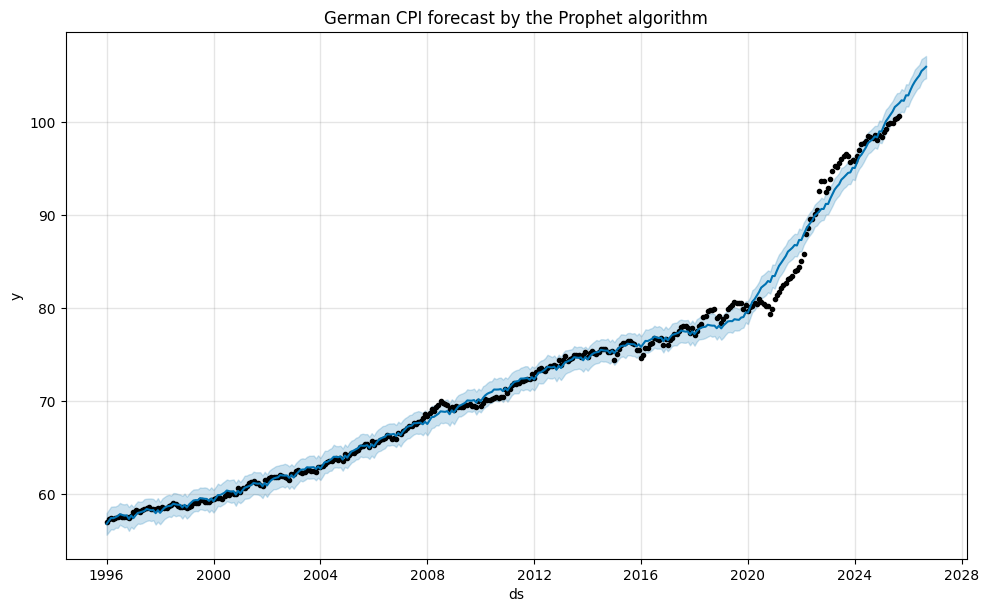

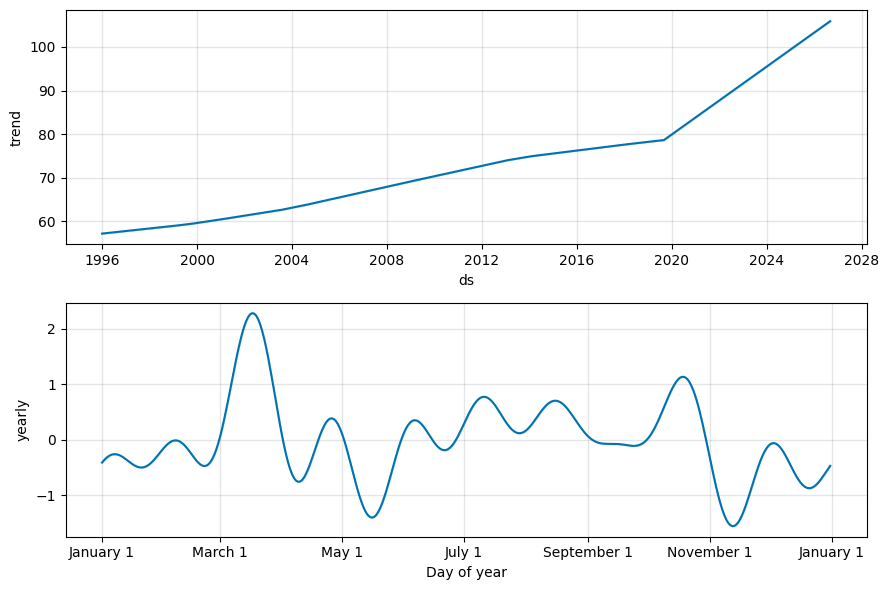

In [12]:
from sklearn.metrics import mean_absolute_percentage_error

predictions = forecast.iloc[-12:]['yhat']
actuals = test['y']

error = mean_absolute_percentage_error(actuals, predictions) * 100
print(f"Average model error (MAPE): {error:.2f}%")

fig1 = model.plot(forecast)
plt.title('German CPI forecast by the Prophet algorithm')
plt.show()

fig2 = model.plot_components(forecast)
plt.show()
